# 06 · Provisão para perdas esperadas (PCLD)

A **Res. CMN 4.966** levou ao sistema financeiro brasileiro, cooperativas de crédito incluídas, o modelo de **perda esperada** da IFRS 9, que vale desde janeiro de 2025. A provisão deixa de esperar o atraso acontecer e passa a antecipar a perda:

| Estágio | Quando | Provisão |
|---|---|---|
| 1 | Na concessão e enquanto o risco não piora | Perda esperada dos **próximos 12 meses** |
| 2 | Aumento significativo do risco de crédito | Perda esperada **até o fim do contrato** |
| 3 | Ativo problemático (default) | Perda da vida toda sobre a exposição em default |

A diferença entre os estágios 1 e 2 é exatamente uma pergunta de **tempo até o default**, e é aí que o modelo de sobrevivência entra:

$$\text{PE}(h) = \sum_{t \le h} \underbrace{P(\text{default no mês } t)}_{\text{riscos competitivos}} \cdot \underbrace{\text{EAD}(t)}_{\text{tabela de amortização}} \cdot \text{LGD} \cdot \frac{1}{(1+i)^t}$$

- **P(default no mês *t*)** vem do modelo escolhido no notebook 05 (Cox único por causa, recalibrado). Quem pré-paga sai do risco e deixa de gerar perda.
- **EAD(*t*)** é o saldo devedor depois de *t* − 1 parcelas pagas.
- **LGD** e o ajuste do EAD são **medidos nos próprios defaults** da base.
- O desconto usa a taxa do contrato.

Os valores estão em **dólares**, a moeda da base. O método é o ponto, não os números de mercado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time_to_default.cox import TRAIN_VINTAGES, design_matrix
from time_to_default.features import PROCESSED_PATH
from time_to_default.loss import ead_matrix, estimate_ead_factor, estimate_lgd, expected_loss
from time_to_default.plotting import BLUE, GRAY, LIGHT_GRAY, ORANGE, percent_axis, savefig, set_style
from time_to_default.predict import CompetingRisksCox, fit_default_scale
from time_to_default.reporting import update_metrics
from time_to_default.survival import life_table

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

data = pd.read_parquet(PROCESSED_PATH)
LOAN_COLS = ["loan_amnt", "int_rate", "installment", "term_months"]

## 1. LGD: quanto se perde quando o contrato quebra

LGD = 1 − recuperação líquida ÷ saldo no default, ponderada pela exposição. As recuperações demoram a acontecer: entre os defaults de 2018, metade ainda não tinha recuperação nenhuma na data da foto. Por isso a LGD usa só os defaults **até 2016**, com pelo menos uns dois anos de cobrança.

In [2]:
defaults = data[data["event"] == 1].copy()
defaults["default_year"] = (defaults["issue_d"] + pd.to_timedelta(defaults["duration"] * 30.44, "D")).dt.year
defaults = defaults[defaults["loan_amnt"] > defaults["total_rec_prncp"]]


def lgd_row(g):
    return pd.Series({"defaults": len(g), "LGD": estimate_lgd(g),
                      "sem recuperação": (g["recoveries"] == 0).mean()})


by_year = defaults.groupby("default_year").apply(lgd_row, include_groups=False)
by_year

,defaults,LGD,sem recuperação
default_year,,,
2008,46.0000,0.9562,0.0652
2009,226.0000,0.9565,0.0310
2010,521.0000,0.9414,0.0038
2011,"1,057.0000",0.9267,0.0104
2012,"2,645.0000",0.9364,0.0053
2013,"6,382.0000",0.9121,0.0271
2014,"14,768.0000",0.8881,0.1220
2015,"31,438.0000",0.8848,0.1977
2016,"61,867.0000",0.9053,0.2271


In [3]:
mature = defaults[defaults["default_year"] <= 2016]
LGD = estimate_lgd(mature)
EAD_FACTOR = estimate_ead_factor(defaults)
segments = pd.concat({
    "prazo": mature.groupby("term_months").apply(lgd_row, include_groups=False),
    "grade": mature.groupby("grade", observed=True).apply(lgd_row, include_groups=False),
    "moradia": mature.groupby("home", observed=True).apply(lgd_row, include_groups=False),
})
print(f"LGD (defaults até 2016): {LGD:.1%}  |  fator de EAD (saldo real ÷ agendado): {EAD_FACTOR:.3f}")
segments

LGD (defaults até 2016): 89.9%  |  fator de EAD (saldo real ÷ agendado): 1.014


defaults    LGD  sem recuperação
prazo   36         72,627.0000 0.8981           0.1832
        60         46,323.0000 0.8998           0.1937
grade   A           6,139.0000 0.9025           0.2535
        B          22,131.0000 0.9020           0.1945
        C          34,939.0000 0.9002           0.1817
        D          27,838.0000 0.8995           0.1814
        E          18,006.0000 0.8969           0.1849
        F           7,726.0000 0.8948           0.1742
        G           2,171.0000 0.8936           0.1580
moradia financiada 51,205.0000 0.8949           0.1825
        aluguel    55,554.0000 0.9042           0.1921
        própria    12,191.0000 0.8975           0.1853

A LGD fica perto de 90% em todos os segmentos, o que é típico de crédito pessoal sem garantia vendido para empresas de cobrança. Por isso uma **LGD única** basta. O saldo real no default fica 1,4% acima do agendado, porque o tomador costuma atrasar um pouco antes de parar.

## 2. O modelo de PD (escolhido no notebook 05)

Cox por causa ajustado nas safras de 2007 a 2015, com o nível do hazard de default recalibrado nos 12 primeiros meses da safra de 2016.

In [4]:
train = design_matrix(data[data["vintage"].isin(TRAIN_VINTAGES)])
model = CompetingRisksCox().fit(train)

v2016 = data[data["vintage"] == 2016]
X2016 = design_matrix(v2016)
target = life_table(v2016.loc[X2016.index, "duration"], v2016.loc[X2016.index, "event"]).loc[12, "cif_default"]
model.default_scale = fit_default_scale(model, X2016, observed=target, horizon=12)
print(f"multiplicador do hazard de default: {model.default_scale:.3f}")

multiplicador do hazard de default: 1.226


## 3. Backtest: exposição em default prevista × realizada

Antes de confiar na provisão, o modelo precisa acertar **quanto dinheiro** entra em default, e não só quantos contratos. A comparação usa horizontes que **todos** os contratos da safra já atingiram, então não há censura a tratar:
- **safra de 2017 em 11 meses** (dez/2017 a nov/2018): fora do ajuste e da recalibração;
- **safra de 2016 em 23 meses**: a recalibração usou só os 12 primeiros meses, então os meses 13 a 23 são novos.

A LGD fica de fora (LGD = 1, sem desconto), para testar só PD × EAD. A exposição realizada é o saldo de fato devido no default.

In [5]:
def backtest(vintage, horizon):
    rows = data[data["vintage"] == vintage]
    X = design_matrix(rows)
    loans = rows.loc[X.index, LOAN_COLS]
    pred = expected_loss(model, X, loans, lgd=1.0, ead_factor=EAD_FACTOR, horizons=(horizon,), discount=False)
    hit = (rows.loc[X.index, "event"] == 1) & (rows.loc[X.index, "duration"] <= horizon)
    realized_ead = (rows.loc[X.index, "loan_amnt"] - rows.loc[X.index, "total_rec_prncp"])[hit].sum()
    exposure = loans["loan_amnt"].sum()
    return {
        "safra": vintage, "horizonte (meses)": horizon, "contratos": len(X),
        "defaults previstos": pred[f"pd_{horizon}m"].sum(), "defaults realizados": int(hit.sum()),
        "EAD em default prevista (% do volume)": pred[f"el_{horizon}m"].sum() / exposure,
        "EAD em default realizada (% do volume)": realized_ead / exposure,
    }


bt = pd.DataFrame([backtest(2017, 11), backtest(2016, 23)]).set_index(["safra", "horizonte (meses)"])
bt["erro (EAD)"] = bt["EAD em default prevista (% do volume)"] / bt["EAD em default realizada (% do volume)"] - 1
bt

,,contratos,defaults previstos,defaults realizados,EAD em default prevista (% do volume),EAD em default realizada (% do volume),erro (EAD)
safra,horizonte (meses),,,,,,
2017,11,400406,"21,583.8452",20037,0.0505,0.0488,0.0355
2016,23,425249,"58,275.4527",54636,0.1105,0.1061,0.0411


## 4. Provisão de uma carteira nova: estágio 1 × estágio 2

Para ilustrar, a **safra de 2018** é tratada como uma carteira recém-concedida. Na concessão, todo contrato está no estágio 1 e provisiona a perda de 12 meses. A coluna do estágio 2 mostra quanto a provisão subiria se o contrato tivesse aumento significativo de risco e passasse a provisionar a vida toda.

In [6]:
book_rows = data[data["vintage"] == 2018]
Xb = design_matrix(book_rows)
book = book_rows.loc[Xb.index, LOAN_COLS + ["grade"]].copy()
el = expected_loss(model, Xb, book[LOAN_COLS], lgd=LGD, ead_factor=EAD_FACTOR, horizons=(12,))
book = book.join(el)


def provision_summary(g):
    volume = g["loan_amnt"].sum()
    return pd.Series({
        "contratos": len(g), "volume (US$ mi)": volume / 1e6,
        "PD 12m": g["pd_12m"].mean(), "PD vida toda": g["pd_lifetime"].mean(),
        "estágio 1 (% do volume)": g["el_12m"].sum() / volume,
        "estágio 2 (% do volume)": g["el_lifetime"].sum() / volume,
        "estágio 2 ÷ estágio 1": g["el_lifetime"].sum() / g["el_12m"].sum(),
    })


total = provision_summary(book).rename("carteira")
by_term = book.groupby("term_months").apply(provision_summary, include_groups=False)
by_grade = book.groupby("grade", observed=True).apply(provision_summary, include_groups=False)
pd.concat([total.to_frame().T, by_term.rename(index=lambda t: f"{t} meses"), by_grade])

,contratos,volume (US$ mi),PD 12m,PD vida toda,estágio 1 (% do volume),estágio 2 (% do volume),estágio 2 ÷ estágio 1
carteira,"354,076.0000","5,480.9785",0.0572,0.1911,0.0412,0.0940,2.2815
36 meses,"253,647.0000","3,334.3308",0.0505,0.1553,0.0337,0.0669,1.9870
60 meses,"100,429.0000","2,146.6484",0.0740,0.2815,0.0529,0.1360,2.5728
A,"98,614.0000","1,516.2798",0.0249,0.0850,0.0178,0.0397,2.2270
B,"101,632.0000","1,578.3751",0.0415,0.1468,0.0297,0.0708,2.3813
C,"90,825.0000","1,418.7896",0.0643,0.2249,0.0462,0.1099,2.3807
D,"48,548.0000",744.1731,0.1040,0.3399,0.0752,0.1696,2.2562
E,"11,887.0000",178.1897,0.1716,0.4886,0.1252,0.2564,2.0472
F,"2,181.0000",38.5063,0.2453,0.6322,0.1759,0.3363,1.9121
G,389.0000,6.6655,0.2621,0.6404,0.1849,0.3392,1.8339


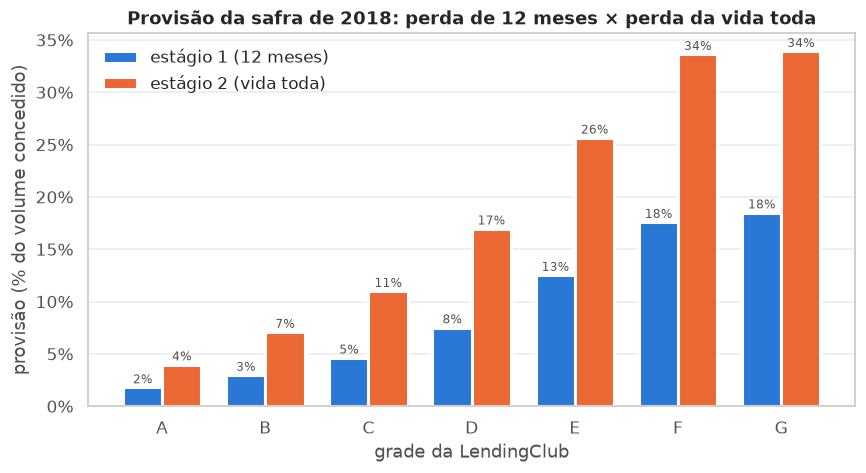

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(by_grade))
w = 0.38
ax.bar(x - w / 2, by_grade["estágio 1 (% do volume)"], w, color=BLUE, label="estágio 1 (12 meses)", edgecolor="white", linewidth=2)
ax.bar(x + w / 2, by_grade["estágio 2 (% do volume)"], w, color=ORANGE, label="estágio 2 (vida toda)", edgecolor="white", linewidth=2)
for xi, (s1, s2) in enumerate(zip(by_grade["estágio 1 (% do volume)"], by_grade["estágio 2 (% do volume)"])):
    ax.text(xi - w / 2, s1 + 0.004, f"{100 * s1:.0f}%", ha="center", fontsize=8, color=GRAY)
    ax.text(xi + w / 2, s2 + 0.004, f"{100 * s2:.0f}%", ha="center", fontsize=8, color=GRAY)
ax.set_xticks(x, by_grade.index)
ax.set_xlabel("grade da LendingClub")
ax.set_ylabel("provisão (% do volume concedido)")
ax.set_title("Provisão da safra de 2018: perda de 12 meses × perda da vida toda")
ax.grid(axis="x", visible=False)
percent_axis(ax)
ax.legend(frameon=False)
savefig(fig, "provision_by_grade")
plt.show()

## 5. Quando a perda esperada acontece

Somando a perda esperada mês a mês na carteira, aparece o mesmo formato do período crítico (notebook 03), agora em **dinheiro**: é o calendário de consumo da provisão.

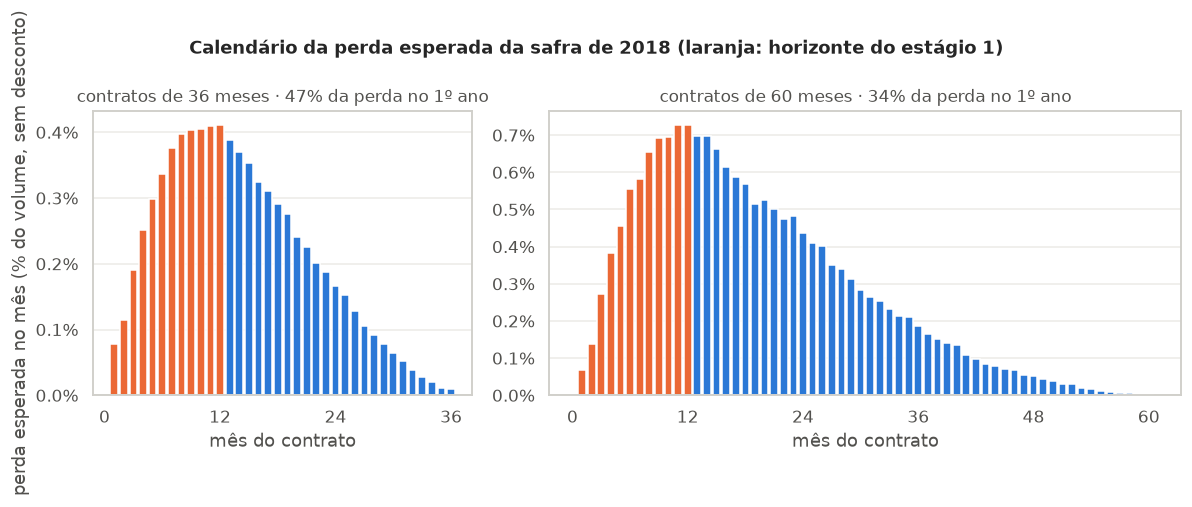

fração da perda no 1º ano: {36: np.float64(0.472), 60: np.float64(0.339)} | mês de pico: {36: 12, 60: 11}


In [8]:
monthly = {36: np.zeros(60), 60: np.zeros(60)}
for i in range(0, len(Xb), 100_000):
    xp = Xb.iloc[i:i + 100_000]
    lp = book[LOAN_COLS].iloc[i:i + 100_000]
    loss = model.default_probabilities(xp) * ead_matrix(lp, EAD_FACTOR) * LGD
    for term in (36, 60):
        rows = (lp["term_months"] == term).to_numpy()
        monthly[term] += loss[rows].sum(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False, gridspec_kw={"width_ratios": [36, 60]})
for ax, term in zip(axes, (36, 60)):
    vol = book.loc[book["term_months"] == term, "loan_amnt"].sum()
    share = monthly[term][:term] / vol
    first_year = monthly[term][:12].sum() / monthly[term][:term].sum()
    ax.bar(np.arange(1, term + 1), share, color=[ORANGE if m <= 12 else BLUE for m in range(1, term + 1)], width=0.8)
    ax.set_title(f"contratos de {term} meses · {first_year:.0%} da perda no 1º ano", fontsize=11,
                 fontweight="normal", color=GRAY)
    ax.set_xticks(range(0, term + 1, 12))
    ax.set_xlabel("mês do contrato")
    ax.grid(axis="x", visible=False)
    percent_axis(ax, decimals=1)
axes[0].set_ylabel("perda esperada no mês (% do volume, sem desconto)")
fig.suptitle("Calendário da perda esperada da safra de 2018 (laranja: horizonte do estágio 1)", fontweight="bold", fontsize=12)
fig.tight_layout()
savefig(fig, "expected_loss_by_month")
plt.show()
share_first_year = {t: monthly[t][:12].sum() / monthly[t][:t].sum() for t in (36, 60)}
peak_month = {t: int(np.argmax(monthly[t]) + 1) for t in (36, 60)}
print("fração da perda no 1º ano:", {t: round(v, 3) for t, v in share_first_year.items()}, "| mês de pico:", peak_month)

## Conclusões

1. **Os parâmetros saem dos próprios dados.**
   - **LGD de 89,9%**, estável entre prazos, grades e tipos de moradia (de 89% a 90%). Isso é típico de crédito sem garantia, cuja recuperação vem em boa parte da venda da dívida.
   - **Saldo no default 1,4% acima do agendado**, porque o tomador atrasa um pouco antes de parar.
2. **O backtest mostra um viés pequeno e conservador.** O modelo prevê 3,6% a mais de exposição em default na safra de 2017 em 11 meses e 4,1% a mais na safra de 2016 em 23 meses. Em número de contratos, o excesso é de 7,7% e 6,7%. Para provisão, errar alguns por cento para cima é o lado prudente.
3. **Mudar de estágio custa caro.** Na safra de 2018, a provisão de estágio 1 é **4,1% do volume**, e a de estágio 2 seria **9,4%** (2,3 vezes):
   - **por prazo:** nos contratos de 60 meses o salto é maior (de 5,3% para 13,6%, 2,6 vezes) do que nos de 36 meses (de 3,4% para 6,7%, 2,0 vezes), porque mais da perda fica depois do 1º ano;
   - **por grade:** vai de 1,8% → 4,0% no grade A até 18,5% → 33,9% no G.

   Para uma cooperativa, isso torna o **critério de aumento significativo de risco** (gatilho do estágio 2) uma das decisões de maior impacto no resultado.
4. **A perda esperada chega antes do pico do hazard.** O hazard fica no máximo entre os meses 12 e 30 (notebook 03), mas a perda esperada por mês tem pico perto do 12º mês e depois cai: o saldo devedor amortiza e a carteira encolhe com os pré-pagamentos. Cerca de **47% da perda da vida toda** dos contratos de 36 meses (34% nos de 60) cai dentro do horizonte do estágio 1.
5. **O modelo de sobrevivência entrega o que a 4.966 pede.** Uma PD por **horizonte** para cada contrato, que serve tanto para o estágio 1 (12 meses) quanto para o estágio 2 (vida toda), e uma estrutura que acomoda pré-pagamento e amortização. Um modelo de classificação comum daria uma PD para um único horizonte fixo.

**Extensão natural:** com dados mensais de comportamento (dias de atraso e saldo atual), o mesmo modelo permitiria comparar a PD da vida toda na data de referência com a da concessão, que é o critério usual de aumento significativo de risco, e alocar cada contrato no estágio certo.

In [9]:
update_metrics("provisioning", {
    "lgd": round(LGD, 4),
    "lgd_defaults_used": int(len(mature)),
    "ead_factor": round(EAD_FACTOR, 4),
    "default_scale": round(float(model.default_scale), 4),
    "backtest": {f"{s}_{h}m": {"ead_error": round(float(r["erro (EAD)"]), 6),
                              "defaults_pred": round(float(r["defaults previstos"])),
                              "defaults_real": int(r["defaults realizados"])}
                 for (s, h), r in bt.iterrows()},
    "book_2018": {
        "loans": int(total["contratos"]), "volume_usd_mi": round(float(total["volume (US$ mi)"]), 1),
        "stage1_pct": round(float(total["estágio 1 (% do volume)"]), 4),
        "stage2_pct": round(float(total["estágio 2 (% do volume)"]), 4),
        "by_term": {int(k): {"stage1_pct": round(float(r["estágio 1 (% do volume)"]), 4),
                             "stage2_pct": round(float(r["estágio 2 (% do volume)"]), 4)} for k, r in by_term.iterrows()},
        "by_grade": {k: {"stage1_pct": round(float(r["estágio 1 (% do volume)"]), 4),
                         "stage2_pct": round(float(r["estágio 2 (% do volume)"]), 4)} for k, r in by_grade.iterrows()},
    },
    "loss_share_first_year": {int(t): round(float(v), 4) for t, v in share_first_year.items()},
    "loss_peak_month": peak_month,
})

{'data': {'raw_loans': 2260668,
  'loans': 2064692,
  'snapshot': '2019-03',
  'observation_end': '2018-11',
  'funnel': [{'etapa': 'base bruta', 'contratos': 2260668, 'removidos': 0},
   {'etapa': 'dentro da política de crédito',
    'contratos': 2257919,
    'removidos': 2749},
   {'etapa': 'pedido individual', 'contratos': 2137209, 'removidos': 120710},
   {'etapa': 'moradia própria, financiada ou aluguel',
    'contratos': 2136024,
    'removidos': 1185},
   {'etapa': 'renda anual positiva', 'contratos': 2136024, 'removidos': 0},
   {'etapa': 'emitido antes do fim da observação',
    'contratos': 2064692,
    'removidos': 71332}],
  'event_share': {'censurado': 0.5047,
   'pré-pagamento': 0.3715,
   'default': 0.1239},
  'term_36_share': 0.72},
 'kaplan_meier': {'term_36': {'cif_default_12m': 0.0487,
   'cif_default_term': 0.1444,
   'naive_km_default_term': 0.206,
   'cif_prepay_term': 0.5623},
  'term_60': {'cif_default_12m': 0.07,
   'cif_default_term': 0.27,
   'naive_km_defaul